# Reinforcement Learning foundations

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shoaibphysics/reasoning-models/blob/main/notebooks/02_rl_foundations.ipynb)

How can an agent use rewards to make better decisions?

We explore action selection and value estimation through multi-armed
bandits and small Markov decision processes.

## 1. Multi-armed bandits

An agent repeatedly chooses among actions without knowing which
gives the highest average reward. Each choice produces a noisy
reward, so one observation may not reveal how good an action is.

The goal is to maximize expected total reward over repeated choices.
Finding a good action early matters because the agent can use that
knowledge to earn more reward on later steps.

At each step $t$, the agent selects an action $A_t$ from $k$ available
actions and observes a reward $R_t$. The true value of an action is
its expected reward:

$$
q_{*}(a) = \mathbb{E}[R_t \mid A_t = a].
$$

We use ten actions with Gaussian rewards. Each action's true value
is sampled once and remains fixed:

$$
q_{*}(a) \sim \mathcal{N}(0, 1).
$$

Selecting an action produces a noisy reward with that mean and
unit variance:

$$
R_t \mid A_t = a \sim \mathcal{N}(q_{*}(a), 1).
$$

The agent cannot see these true values. It maintains a separate
estimate for each action using the rewards observed when selecting
that action.

Learning and decision-making happen together. After receiving a
reward, the agent updates the selected action's estimate and uses
its current estimates to guide the next choice. Exploration helps
it discover better actions; exploitation uses what it has learned.

Estimates are retained throughout a run. A new bandit starts with
fresh estimates because its action values may be different.

Reference: Sutton and Barto, [Reinforcement Learning: An Introduction](https://www2.imm.dtu.dk/courses/02465/pensum/sutton2018.pdf),
Chapter 2, Sections 2.1–2.4.

In [1]:
import torch

def make_bandit(n_actions=10, seed=0):
    generator = torch.Generator().manual_seed(seed)
    return torch.randn(n_actions, generator=generator)

def sample_reward(true_values, action, generator):
    noise = torch.randn((), generator=generator)
    return (true_values[action] + noise).item()

true_values = make_bandit(n_actions=10, seed=42)

print("True action values:", true_values)
print("Optimal action:", true_values.argmax().item())
print("Highest expected reward:", round(true_values.max().item(), 3)) # Actions are numbered `0-9` in the code.

True action values: tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229, -0.1863,  2.2082, -0.6380,
         0.4617,  0.2674])
Optimal action: 6
Highest expected reward: 2.208


### Estimating action values

After selecting action $a$ a total of $n$ times, its sample-average
estimate is

$$
Q_n(a) = \frac{1}{n}\sum_{i=1}^{n} R_i(a),
$$

where $R_i(a)$ is the reward from the $i$-th selection of that action.

We can compute the same average incrementally:

$$
Q_n(a)
= Q_{n-1}(a) + \frac{R_n(a) - Q_{n-1}(a)}{n}.
$$

The new estimate equals the previous estimate plus a correction.
The difference between the observed reward and the previous estimate
determines the direction of the correction, while $1/n$ determines
its size.

Each update needs only the previous estimate, the new reward, and the
selection count. We initialize $Q_0(a)=0$ and each count to zero.
Here, $n$ counts selections of action $a$, not total time steps.

In [2]:
def update_estimate(estimates, counts, action, reward):
    counts[action] += 1
    estimates[action] += (reward - estimates[action]) / counts[action]

estimates = torch.zeros_like(true_values)
counts = torch.zeros(len(true_values), dtype=torch.long)

reward_generator = torch.Generator().manual_seed(43)
action = 0
observed_rewards = []

for _ in range(5):
    reward = sample_reward(true_values, action, reward_generator)
    observed_rewards.append(reward)

    update_estimate(estimates, counts, action, reward)

    print(f"Count: {counts[action].item()} | Reward: {reward:.3f} | Estimate: {estimates[action].item():.3f}")

sample_mean = torch.tensor(observed_rewards).mean()

print()
print("Incremental estimate:", round(estimates[action].item(), 6))
print("Direct sample mean:", round(sample_mean.item(), 6))
print("True action value:", round(true_values[action].item(), 6))

Count: 1 | Reward: -0.312 | Estimate: -0.312
Count: 2 | Reward: -0.369 | Estimate: -0.340
Count: 3 | Reward: 0.980 | Estimate: 0.100
Count: 4 | Reward: 1.815 | Estimate: 0.529
Count: 5 | Reward: 1.529 | Estimate: 0.729

Incremental estimate: 0.728615
Direct sample mean: 0.728615
True action value: 0.33669


### Epsilon-greedy action selection

We want to identify the action with the highest expected reward.
Because individual rewards are noisy, we estimate each action's
expected reward by averaging the rewards observed when selecting it.

Each action has its own estimate and selection count. Switching
actions changes which estimate we update; it does not reset any
previous estimates.

For example, consider the sequence A, A, A, B, A, B:

| Overall step | Selected action | Estimate updated |
|---|---|---|
| 1 | A | $Q_1(A)$ |
| 2 | A | $Q_2(A)$ |
| 3 | A | $Q_3(A)$ |
| 4 | B | $Q_1(B)$ |
| 5 | A | $Q_4(A)$ |
| 6 | B | $Q_2(B)$ |

At step 6, B has been selected twice, so we update $Q_2(B)$.
A retains its estimate $Q_4(A)$. Each subscript counts observations
of that particular action, not overall steps.

To select an action, we compare the current estimates. We write
$Q(a)$ as shorthand for the latest estimate of action $a$. After
the sequence above, $Q(A)=Q_4(A)$ and $Q(B)=Q_2(B)$.

Always choosing the highest estimate can overlook a better action
that has not been tried enough. Epsilon-greedy balances using our
current estimates with gathering more information:

$$
A_t =
\begin{cases}
\text{a uniformly random action}, & \text{with probability }\epsilon,\\
\arg\max_a Q(a), & \text{with probability }1-\epsilon.
\end{cases}
$$

We break ties randomly when several actions share the highest
estimate. Exploration samples from all actions, including those
with the highest estimate.

With $\epsilon=0.1$, each step has a 10% probability of exploration
and a 90% probability of a greedy choice. After receiving the reward,
we update only the selected action's estimate and count.

In [3]:
def choose_action(estimates, epsilon, generator):
    if torch.rand((), generator=generator).item() < epsilon:
        return torch.randint(len(estimates), (), generator=generator).item()

    best_actions = torch.where(estimates == estimates.max())[0]
    index = torch.randint(len(best_actions), (), generator=generator).item()
    return best_actions[index].item()

def run_bandit(true_values, epsilon=0.1, n_steps=1000, seed=0):
    estimates = torch.zeros_like(true_values)
    counts = torch.zeros(len(true_values), dtype=torch.long)

    rewards = torch.zeros(n_steps)
    actions = torch.zeros(n_steps, dtype=torch.long)

    action_generator = torch.Generator().manual_seed(seed)
    reward_generator = torch.Generator().manual_seed(seed + 1)

    for t in range(n_steps):
        action = choose_action(estimates, epsilon, action_generator)
        reward = sample_reward(true_values, action, reward_generator)
        update_estimate(estimates, counts, action, reward)
        actions[t] = action
        rewards[t] = reward

    return {
        "estimates": estimates,
        "counts": counts,
        "actions": actions,
        "rewards": rewards }

result = run_bandit( true_values,epsilon=0.1,n_steps=1000,seed=44)
print("Action | True value | Estimate | Count")
for action in range(len(true_values)):
    print(f"{action:6d} | {true_values[action].item():10.3f} | {result['estimates'][action].item():8.3f} | {result['counts'][action].item():5d}" )

print()
print("Total selections:", result["counts"].sum().item())
print("Estimated best action:", result["estimates"].argmax().item())
print("True best action:", true_values.argmax().item())
print("Average reward:", round(result["rewards"].mean().item(), 3))

Action | True value | Estimate | Count
     0 |      0.337 |    0.365 |    63
     1 |      0.129 |    0.521 |    10
     2 |      0.234 |    0.725 |    10
     3 |      0.230 |    0.112 |    14
     4 |     -1.123 |   -0.582 |    16
     5 |     -0.186 |    0.251 |    11
     6 |      2.208 |    2.215 |   838
     7 |     -0.638 |   -0.804 |    12
     8 |      0.462 |    0.191 |    17
     9 |      0.267 |    0.651 |     9

Total selections: 1000
Estimated best action: 6
True best action: 6
Average reward: 1.886


### Comparing exploration rates

One bandit is not enough to compare action-selection strategies.
Its action values and early rewards can strongly influence the result.

We compare three exploration rates across 500 bandits, running each
for 1,000 steps:

- $\epsilon=0$: always make a greedy choice.
- $\epsilon=0.01$: explore with 1% probability at each step.
- $\epsilon=0.1$: explore with 10% probability at each step.

All three settings use the same bandits. Each run starts with zero
estimates and counts.

For each exploration rate, we average the reward at each step across
the bandits:

$$
\bar{R}_t = \frac{1}{B}\sum_{b=1}^{B} R_t^{(b)},
$$

where $B$ is the number of bandits and $R_t^{(b)}$ is the reward
received at step $t$ in bandit $b$.

Each point on the plot therefore represents the average reward
across bandits at that particular step.

epsilon=0 | Mean reward across all runs and steps: 1.047
epsilon=0.01 | Mean reward across all runs and steps: 1.203
epsilon=0.1 | Mean reward across all runs and steps: 1.318


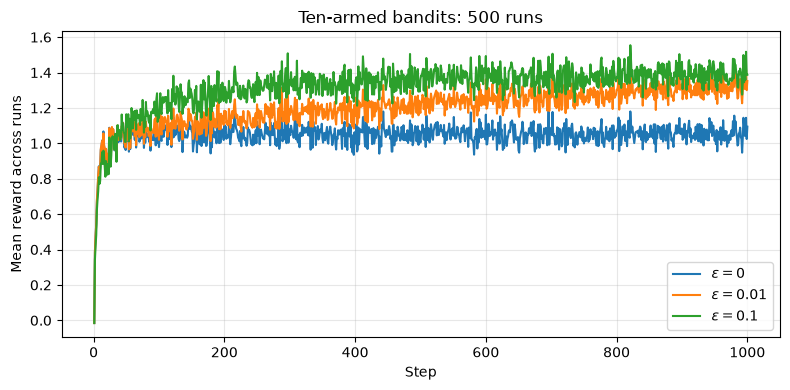

In [4]:
epsilons = [0.0, 0.01, 0.1]
n_runs = 500
n_steps = 1000

bandits = [make_bandit(n_actions=10, seed=1000 + run) for run in range(n_runs)]
average_rewards = {}

for epsilon in epsilons:
    rewards = torch.zeros(n_runs, n_steps)

    for run, values in enumerate(bandits):
        run_result = run_bandit(
            values,
            epsilon=epsilon,
            n_steps=n_steps,
            seed=10000 + 2 * run,
        )
        rewards[run] = run_result["rewards"]

    average_rewards[epsilon] = rewards.mean(dim=0)

    print(f"epsilon={epsilon:g} | Mean reward across all runs and steps: {rewards.mean().item():.3f}")

import matplotlib.pyplot as plt

steps = range(1, n_steps + 1)

fig, ax = plt.subplots(figsize=(8, 4))

for epsilon in epsilons:
    ax.plot(steps,average_rewards[epsilon].numpy(),label=fr"$\epsilon={epsilon:g}$")

ax.set_xlabel("Step")
ax.set_ylabel("Mean reward across runs")
ax.set_title(f"Ten-armed bandits: {n_runs} runs")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

Across these 500 runs, $\epsilon=0.1$ achieved the highest average
reward over 1,000 steps. Purely greedy selection improved quickly
at first but then levelled off. With $\epsilon=0.01$, rewards
continued to improve more gradually.

Exploration helped the agent discover better actions instead of
relying only on those that looked promising early. The useful
balance between exploration and exploitation depends on the
problem and the number of steps available for learning.

## 2. Markov decision processes

In a Markov decision process, an action affects both the immediate
reward and the state the agent encounters next. Decisions must
therefore account for future rewards.

At step $t$, the agent observes state $S_t$ and selects action $A_t$.
The environment produces reward $R_{t+1}$ and next state $S_{t+1}$.

The Markov property means that the current state contains the
information needed to predict the next state and reward, given
the action. The full history is not required.

The transition probabilities are

$$
p(s' \mid s,a)
=
\Pr(S_{t+1}=s' \mid S_t=s,A_t=a).
$$

We write $r(s,a,s')$ for the expected reward associated with a
transition from $s$ to $s'$ after taking action $a$.

### Dynamic programming

Dynamic programming uses known transition probabilities and rewards
to calculate state values and find a policy that maximizes expected
return.

A policy specifies how the agent chooses actions in each state.
The discounted return is

$$
G_t = \sum_{k=0}^{\infty}\gamma^k R_{t+k+1},
$$

where $0 \leq \gamma < 1$. The discount factor controls the weight
given to future rewards.

The value of a state under policy $\pi$ is its expected return:

$$
v_\pi(s) = \mathbb{E}_\pi[G_t \mid S_t=s].
$$

The optimal state value is the highest expected return achievable
from that state:

$$
v_*(s) = \max_\pi v_\pi(s).
$$

An optimal policy $\pi_*$ achieves the optimal value in every state:

$$
v_{\pi_*}(s)=v_*(s)
\qquad \text{for every state }s.
$$

The optimal value function tells us the highest expected return
achievable from each state. An optimal policy tells us how to
choose actions to achieve that return. More than one policy
may be optimal.

#### Value iteration

Value iteration repeatedly compares the actions available in each
state. For each action, we calculate the expected immediate reward
plus the discounted value of the next state, then keep the largest
result.

Writing $V(s)$ for our current estimate of $v_*(s)$, the update is

$$
V(s)
\leftarrow
\max_a
\sum_{s'} p(s' \mid s,a)
\left[r(s,a,s')+\gamma V(s')\right].
$$

We repeat these updates using the current available values until
the estimates change by less than a chosen tolerance.

These updates are calculations using the known model. They do not
require sampling interactions with the environment.

##### Recycling robot

A robot collects empty cans using a rechargeable battery. Its state
is either high or low battery.

The robot can search for cans or wait. At low battery, it can also
recharge. Searching earns a reward but risks draining the battery.
Waiting earns a smaller reward, while recharging earns no immediate
reward.

Let $\alpha$ be the probability of remaining at high battery after
searching from high battery. Let $\beta$ be the probability of
remaining at low battery after searching from low battery.

The rewards are $r_{\mathrm{search}}$ for a successful search,
$r_{\mathrm{wait}}$ for waiting, and $r_{\mathrm{rescue}}<0$
when the battery runs out.

| State | Action | Next state | Probability | Reward |
|---|---|---|---|---|
| High | Search | High | $\alpha$ | $r_{\mathrm{search}}$ |
| High | Search | Low | $1-\alpha$ | $r_{\mathrm{search}}$ |
| High | Wait | High | $1$ | $r_{\mathrm{wait}}$ |
| Low | Search | Low | $\beta$ | $r_{\mathrm{search}}$ |
| Low | Search | High | $1-\beta$ | $r_{\mathrm{rescue}}$ |
| Low | Wait | Low | $1$ | $r_{\mathrm{wait}}$ |
| Low | Recharge | High | $1$ | $0$ |

A failed search requires rescue and recharging, so the next state
is high battery. The rescue reward replaces the successful-search
reward for that outcome. The task continues after recharging.

We initialize both state values at zero. Each iteration compares
the available actions, updates the high-battery value, then updates
the low-battery value using the newly calculated high-battery value.

Reference: Sutton and Barto,
[Reinforcement Learning: An Introduction](https://www2.imm.dtu.dk/courses/02465/pensum/sutton2018.pdf),
Chapter 3, Example 3.3.

Converged in 120 iterations.
Optimal value at high: 25.4237
Optimal value at low:  22.8813


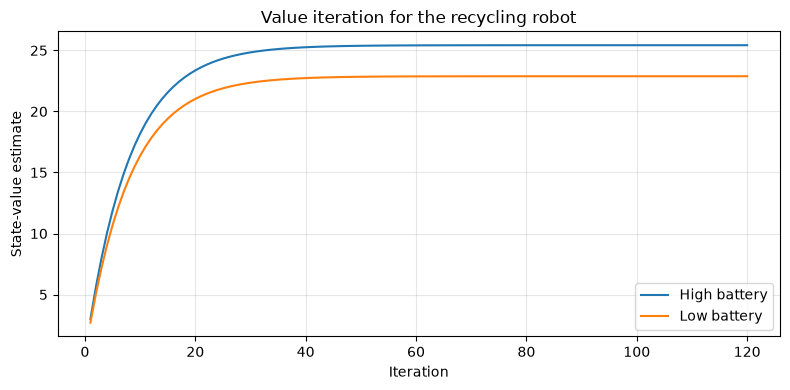

In [5]:
import torch
import matplotlib.pyplot as plt

alpha = 0.8
beta = 0.6
r_search = 3.0
r_wait = 1.0
r_rescue = -3.0
gamma = 0.9


def solve_values(tol=1e-6, max_iter=1000):
    v_high = torch.tensor(0.0, dtype=torch.float64)
    v_low = torch.tensor(0.0, dtype=torch.float64)

    high_history = []
    low_history = []

    for i in range(max_iter):
        old_high, old_low = v_high, v_low

        # Update the high-battery value.
        search_high = r_search + gamma * (alpha * v_high + (1 - alpha) * v_low)
        wait_high = r_wait + gamma * v_high
        v_high = torch.maximum(search_high, wait_high)

        # Update the low-battery value using the updated high value.
        search_low = (beta * r_search + (1 - beta) * r_rescue+ gamma * ((1 - beta) * v_high + beta * v_low))
        wait_low = r_wait + gamma * v_low
        recharge = gamma * v_high
        v_low = torch.stack([search_low, wait_low, recharge]).max()

        high_history.append(v_high.item())
        low_history.append(v_low.item())

        change = torch.maximum((v_high - old_high).abs(),(v_low - old_low).abs(),).item()

        if change < tol:
            print(f"Converged in {i + 1} iterations.")
            break
    else:
        raise RuntimeError("Value updates did not converge within max_iter.")

    return v_high.item(), v_low.item(), high_history, low_history


v_high_star, v_low_star, high_history, low_history = solve_values()

print(f"Optimal value at high: {v_high_star:.4f}")
print(f"Optimal value at low:  {v_low_star:.4f}")

iterations = range(1, len(high_history) + 1)

plt.figure(figsize=(8, 4))

plt.plot(iterations, high_history, label="High battery")
plt.plot(iterations, low_history, label="Low battery")

plt.xlabel("Iteration")
plt.ylabel("State-value estimate")
plt.title("Value iteration for the recycling robot")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Policy iteration

Policy iteration alternates between evaluating a policy and
improving it. Here, $\pi(s)$ specifies one action for each state.

**Policy evaluation:** Keep the policy fixed. Here, $V(s)$ estimates
$v_\pi(s)$, the value of the current policy. Repeat the updates
until the largest change falls below the tolerance:

$$
V(s)
\leftarrow
\sum_{s'} p(s' \mid s,\pi(s))
\left[r(s,\pi(s),s')+\gamma V(s')\right].
$$

**Policy improvement:** Use the evaluated state values to choose
the action with the highest expected return in each state:

$$
\pi_{\mathrm{new}}(s)
=
\arg\max_a
\sum_{s'} p(s' \mid s,a)
\left[r(s,a,s')+\gamma V(s')\right].
$$

We alternate these two steps until policy improvement leaves the
policy unchanged.

Value iteration takes the maximum over actions during each value
update. Policy iteration evaluates the selected actions first,
then updates the policy in a separate step.

##### Car rental

A rental company operates at two locations. Each rented car earns
income, while moving cars between locations incurs a cost.
The goal is to choose overnight transfers that maximize expected
discounted income minus moving costs.

The state $s=(i,j)$ records the number of cars at the two locations
at the end of a day. The action $a$ specifies the overnight transfer:

- $a>0$: move cars from location 1 to location 2.
- $a<0$: move cars from location 2 to location 1.
- $a=0$: leave the cars where they are.

At most $M$ cars can be moved overnight, and the source location
must have enough cars. Each location holds at most $C$ cars;
any excess after transfers or returns is removed from the system.

After the transfer, the available inventories are

$$
x_1=\min(C,i-a),
\qquad
x_2=\min(C,j+a).
$$

Daily rental requests and returns are independent Poisson random
variables. For a count $N$ with mean $\lambda$,

$$
\Pr(N=n)=e^{-\lambda}\frac{\lambda^n}{n!}.
$$

Each location has its own request and return rates. If $D_1$ and
$D_2$ are the rental requests, the numbers of fulfilled rentals are

$$
L_1=\min(x_1,D_1),
\qquad
L_2=\min(x_2,D_2).
$$

With rental income $r_{\mathrm{rent}}$ per car and transfer cost
$c_{\mathrm{move}}$ per car, the reward is

$$
R=r_{\mathrm{rent}}(L_1+L_2)-c_{\mathrm{move}}|a|.
$$

After returns $U_1$ and $U_2$, the next state is

$$
s'
=
\left(
\min(C,x_1-L_1+U_1),
\min(C,x_2-L_2+U_2)
\right).
$$

Returned cars become available for the following day.

We begin with a policy that moves no cars. Policy evaluation
calculates its expected return, averaging over requests and returns.
Policy improvement then selects the best transfer in each state.
We repeat until the policy stops changing.

Reference: Sutton and Barto,
[Reinforcement Learning: An Introduction](https://www2.imm.dtu.dk/courses/02465/pensum/sutton2018.pdf),
Chapter 4, Example 4.2.

Policy converged after 5 improvement steps.


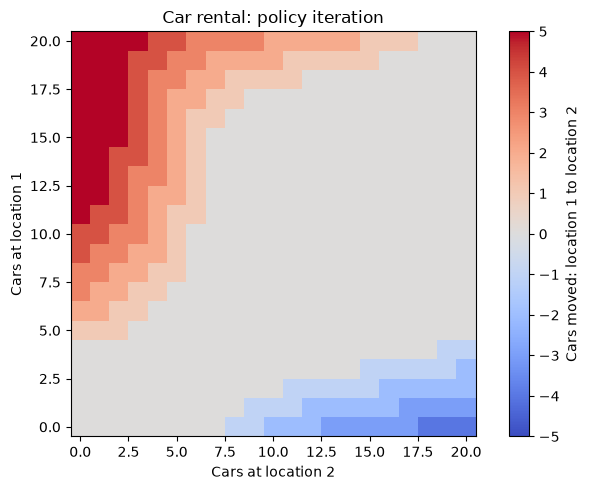

In [ ]:
import torch
import matplotlib.pyplot as plt

max_cars = 20
max_move = 5
rental_reward = 10.0
move_cost = 2.0
discount = 0.9
request_rates = (3.0, 4.0)
return_rates = (3.0, 2.0)
tol = 1e-6
dtype = torch.float64


def poisson_probs(rate):
    probs = torch.zeros(max_cars + 1, dtype=dtype)
    probs[0] = torch.exp(torch.tensor(-rate, dtype=dtype))

    for n in range(1, max_cars):
        probs[n] = probs[n - 1] * rate / n

    # The last entry includes all counts of max_cars or more.
    probs[-1] = 1.0 - probs[:-1].sum()
    return probs


def location_model(request_rate, return_rate):
    requests = poisson_probs(request_rate)
    returns = poisson_probs(return_rate)
    counts = torch.arange(max_cars + 1)
    transitions = torch.zeros((max_cars + 1, max_cars + 1), dtype=dtype)
    income = torch.zeros(max_cars + 1, dtype=dtype)

    for cars in range(max_cars + 1):
        for demand in range(max_cars + 1):
            rented = min(cars, demand)
            income[cars] += requests[demand] * rental_reward * rented

            next_cars = (cars - rented + counts).clamp(max=max_cars)
            transitions[cars].scatter_add_(
                0, next_cars, requests[demand] * returns
            )

    return transitions, income


p1, income1 = location_model(request_rates[0], return_rates[0])
p2, income2 = location_model(request_rates[1], return_rates[1])

counts = torch.arange(max_cars + 1)
cars1, cars2 = torch.meshgrid(counts, counts, indexing="ij")
actions = torch.arange(-max_move, max_move + 1)

values = torch.zeros((max_cars + 1, max_cars + 1), dtype=dtype)
policy = torch.zeros_like(values, dtype=torch.long)

# Prepare inventories and expected rewards for every state and action.
valid = (actions <= cars1[..., None]) & (-actions <= cars2[..., None])
after1 = (cars1[..., None] - actions).clamp(0, max_cars)
after2 = (cars2[..., None] + actions).clamp(0, max_cars)
rewards = income1[after1] + income2[after2] - move_cost * actions.abs()

for iteration in range(50):
    # Policy evaluation: hold the selected actions fixed.
    selected = (policy + max_move).unsqueeze(-1)
    start1 = after1.gather(-1, selected).squeeze(-1)
    start2 = after2.gather(-1, selected).squeeze(-1)
    policy_rewards = rewards.gather(-1, selected).squeeze(-1)

    for _ in range(1000):
        # Average next-state values over both locations' transitions.
        future = p1 @ values @ p2.T
        updated = policy_rewards + discount * future[start1, start2]

        change = (updated - values).abs().max().item()
        values = updated
        if change < tol:
            break
    else:
        raise RuntimeError("Policy evaluation did not converge.")

    # Policy improvement: compare all feasible actions.
    future = p1 @ values @ p2.T
    action_values = rewards + discount * future[after1, after2]
    action_values = action_values.masked_fill(~valid, -torch.inf)

    best_values, best_indices = action_values.max(dim=-1)
    current_values = action_values.gather(-1, selected).squeeze(-1)

    # Keep the current action when alternatives are tied numerically.
    new_policy = torch.where(
        best_values > current_values + 1e-10,
        actions[best_indices],
        policy)

    if torch.equal(new_policy, policy):
        print(f"Policy converged after {iteration + 1} improvement steps.")
        break

    policy = new_policy
else:
    raise RuntimeError("Policy iteration did not converge.")

plt.figure(figsize=(7, 5))
plt.imshow(
    policy.numpy(),
    origin="lower",
    cmap="coolwarm",
    vmin=-max_move,
    vmax=max_move,
    extent=(-0.5, max_cars + 0.5, -0.5, max_cars + 0.5))
plt.colorbar(label="Cars moved: location 1 to location 2", ticks=actions.tolist())
plt.xlabel("Cars at location 2")
plt.ylabel("Cars at location 1")
plt.title("Car rental: policy iteration")
plt.tight_layout()
plt.show()